In [5]:
import pandas as pd
url = "https://raw.githubusercontent.com/yamini-12-arch/Student-Performance-Prediction/main/Student_Performance_Dataset.csv"
df = pd.read_csv(url)
print(df.head())
print(df.info())
print(df.isnull().sum())

  Student_ID  Age  Gender  Class  Study_Hours_Per_Day  Attendance_Percentage  \
0      S0001   15    Male     12                  1.0                     65   
1      S0002   19  Female      9                  1.6                     58   
2      S0003   14  Female     12                  3.6                     64   
3      S0004   18  Female      9                  5.5                     68   
4      S0005   14    Male     10                  5.0                     80   

  Parental_Education Internet_Access Extracurricular_Activities  Math_Score  \
0       Postgraduate              No                         No          40   
1           Graduate              No                        Yes          80   
2        High School             Yes                        Yes          83   
3       Postgraduate             Yes                         No          68   
4        High School             Yes                         No          41   

   Science_Score  English_Score  Previous_Ye

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

In [7]:
df = pd.read_csv("Student_Performance_Dataset.csv")

In [8]:
df.head()

,Student_ID,Age,Gender,Class,Study_Hours_Per_Day,Attendance_Percentage,Parental_Education,Internet_Access,Extracurricular_Activities,Math_Score,Science_Score,English_Score,Previous_Year_Score,Final_Percentage,Performance_Level,Pass_Fail
0,S0001,15,Male,12,1.0,65,Postgraduate,No,No,40,39,72,81,50.33,Average,Pass
1,S0002,19,Female,9,1.6,58,Graduate,No,Yes,80,44,35,47,53.00,Average,Pass
2,S0003,14,Female,12,3.6,64,High School,Yes,Yes,83,73,59,58,71.67,Good,Pass
3,S0004,18,Female,9,5.5,68,Postgraduate,Yes,No,68,48,77,54,64.33,Average,Pass
4,S0005,14,Male,10,5.0,80,High School,Yes,No,41,46,36,68,41.00,Poor,Fail


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  5000 non-null   object 
 1   Age                         5000 non-null   int64  
 2   Gender                      5000 non-null   object 
 3   Class                       5000 non-null   int64  
 4   Study_Hours_Per_Day         5000 non-null   float64
 5   Attendance_Percentage       5000 non-null   int64  
 6   Parental_Education          5000 non-null   object 
 7   Internet_Access             5000 non-null   object 
 8   Extracurricular_Activities  5000 non-null   object 
 9   Math_Score                  5000 non-null   int64  
 10  Science_Score               5000 non-null   int64  
 11  English_Score               5000 non-null   int64  
 12  Previous_Year_Score         5000 non-null   int64  
 13  Final_Percentage            5000 

In [10]:
print("Rows and Columns:", df.shape)

Rows and Columns: (5000, 16)


In [11]:
print(df.columns)

Index(['Student_ID', 'Age', 'Gender', 'Class', 'Study_Hours_Per_Day',
       'Attendance_Percentage', 'Parental_Education', 'Internet_Access',
       'Extracurricular_Activities', 'Math_Score', 'Science_Score',
       'English_Score', 'Previous_Year_Score', 'Final_Percentage',
       'Performance_Level', 'Pass_Fail'],
      dtype='object')


In [12]:
df.isnull().sum()

,0
Student_ID,0
Age,0
Gender,0
Class,0
Study_Hours_Per_Day,0
Attendance_Percentage,0
Parental_Education,0
Internet_Access,0
Extracurricular_Activities,0
Math_Score,0


In [13]:
df.fillna(df.mean(numeric_only=True), inplace=True)

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.drop_duplicates(inplace=True)

In [16]:
df.dtypes

,0
Student_ID,object
Age,int64
Gender,object
Class,int64
Study_Hours_Per_Day,float64
Attendance_Percentage,int64
Parental_Education,object
Internet_Access,object
Extracurricular_Activities,object
Math_Score,int64


In [17]:
df.describe()

,Age,Class,Study_Hours_Per_Day,Attendance_Percentage,Math_Score,Science_Score,English_Score,Previous_Year_Score,Final_Percentage
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,16.508800,10.496400,3.287260,74.919800,67.754800,66.895400,67.782800,67.282200,67.477656
std,1.718637,1.106812,1.587979,14.673842,18.724487,19.141195,19.248473,16.157511,10.964081
min,14.000000,9.000000,0.500000,50.000000,35.000000,35.000000,35.000000,40.000000,36.330000
25%,15.000000,10.000000,1.900000,62.000000,52.000000,50.000000,51.000000,53.000000,59.670000
50%,17.000000,10.000000,3.300000,75.000000,68.000000,67.000000,68.000000,67.000000,67.330000
75%,18.000000,11.000000,4.700000,88.000000,84.000000,83.000000,85.000000,81.000000,75.330000
max,19.000000,12.000000,6.000000,100.000000,100.000000,100.000000,100.000000,95.000000,98.330000


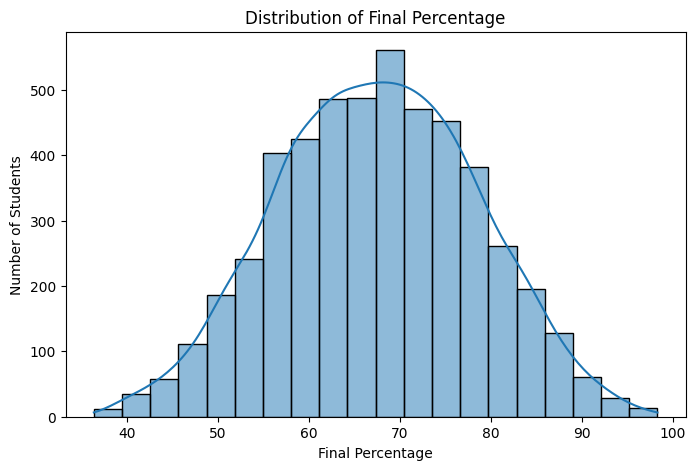

In [38]:
plt.figure(figsize=(8,5))

sns.histplot(df['Final_Percentage'], bins=20, kde=True)

plt.title("Distribution of Final Percentage")
plt.xlabel("Final Percentage")
plt.ylabel("Number of Students")

plt.show()

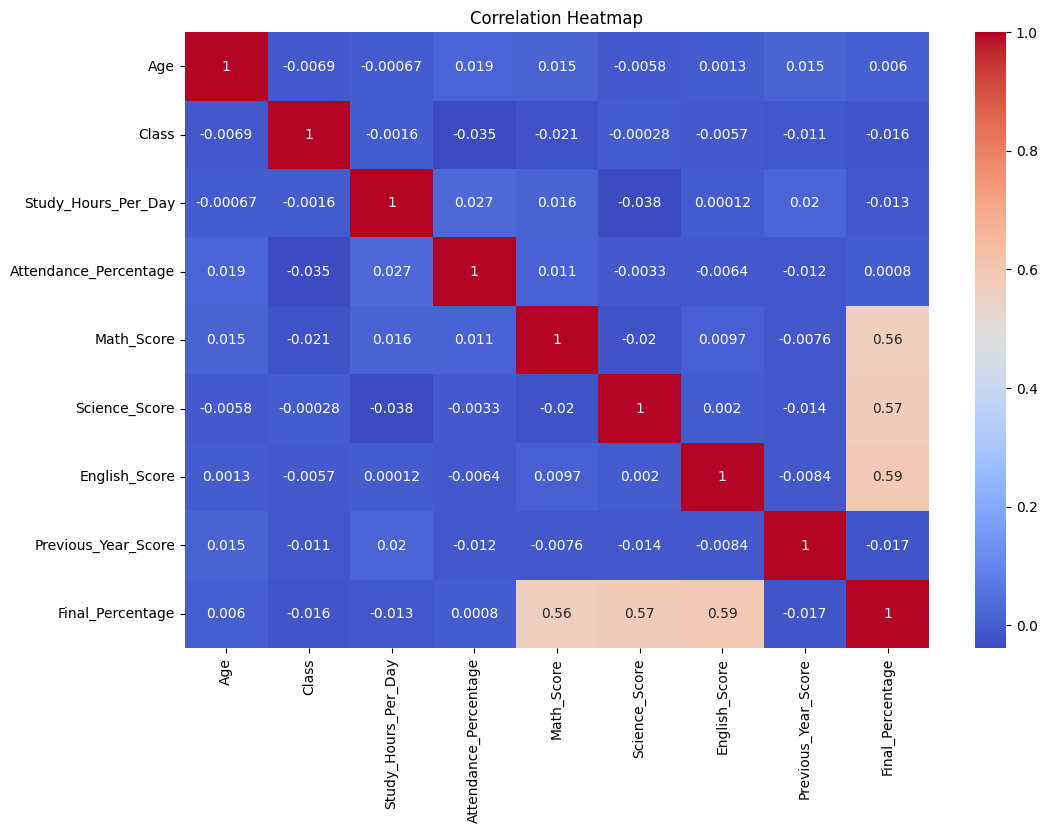

In [39]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [40]:
df = pd.get_dummies(df, drop_first=True)

In [42]:
X = df.drop("Final_Percentage", axis=1)
y = df["Final_Percentage"]

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [44]:
from sklearn.linear_model import LinearRegression

In [45]:
model = LinearRegression()

In [46]:
model.fit(X_train, y_train)

LinearRegression()

In [47]:
y_pred = model.predict(X_test)

In [48]:
prediction_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

prediction_df.head(10)

,Actual,Predicted
0,59.33,59.333634
1,63.33,63.333510
2,61.00,60.999766
3,69.00,68.998981
4,72.67,72.666762
5,69.00,68.999606
6,59.00,58.999476
7,82.00,81.998448
8,63.33,63.333261
9,54.00,53.999247


In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error: 0.0024110677591711325
Mean Squared Error: 7.824417201338897e-06
R2 Score: 0.9999999341525131


In [50]:
import joblib

joblib.dump(model, "student_performance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [51]:
y_pred = model.predict(X_test)

In [52]:
prediction_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

prediction_df.head(10)

,Actual,Predicted
0,59.33,59.333634
1,63.33,63.333510
2,61.00,60.999766
3,69.00,68.998981
4,72.67,72.666762
5,69.00,68.999606
6,59.00,58.999476
7,82.00,81.998448
8,63.33,63.333261
9,54.00,53.999247


In [53]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error: 0.0024110677591711325
Mean Squared Error: 7.824417201338897e-06
R2 Score: 0.9999999341525131


In [54]:
import joblib

joblib.dump(model, "student_performance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [55]:
new_student = X.iloc[[0]]
predicted_score = model.predict(new_student)

print("Predicted Overall Score:", predicted_score[0])

Predicted Overall Score: 50.32999999999988
